In [3]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict
from langchain_groq import ChatGroq
from langgraph.checkpoint.memory import InMemorySaver
from langchain_core.runnables import RunnableConfig
import os 
from dotenv import load_dotenv

In [4]:
load_dotenv()

True

In [5]:
chatmodel= ChatGroq(model="openai/gpt-oss-120b", temperature=0.2, api_key=os.getenv("GROQ_API_KEY"))

In [6]:
class JokeState(TypedDict):
    topic:str
    joke:str
    explaination:str
    

In [7]:
def gen_joke(state: JokeState):
    prompt= f" You are the expert joke write on the provided topic write any kind of joke on the tpoic but that has to be some meaning in that- {state['topic']}"
    response= chatmodel.invoke(prompt)
    return{'joke':response}

In [8]:
def exp_joke(state:JokeState):
    prompt= f" you are the expert joke explainer so explain the joke in only good manner{state['joke']}"
    response= chatmodel.invoke(prompt)
    return{'explaination':response}

In [9]:
graph= StateGraph(JokeState)

graph.add_node("generate_joke",gen_joke)
graph.add_node("explain_joke",exp_joke)

graph.add_edge(START, "generate_joke")
graph.add_edge("generate_joke","explain_joke")
graph.add_edge("explain_joke",END)

checkpointer=InMemorySaver()

workflow=graph.compile(checkpointer=checkpointer)


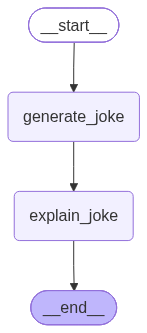

In [10]:
workflow

In [22]:
config1={"configurable":{"thread_id":"1"}}
workflow.invoke({"topic":"pizza"},config=config1)

{'topic': 'pizza',
 'joke': AIMessage(content='**Joke:**  \nWhy did the slice of pizza go to therapy?  \n\nBecause it finally realized it couldn’t keep *topping* its feelings—so it learned to let the cheese melt, the sauce flow, and the crust stay grounded.\n\n**The meaning:**  \nJust like a pizza, we’re made of many layers—some spicy, some cheesy, some a little crusty. When we try to hold everything together without letting anything settle, we end up feeling overloaded. The secret to a good life (and a good pizza) is to let each layer do its part, accept the heat, and stay grounded in the crust that supports you. 🍕✨', additional_kwargs={'reasoning_content': 'The user wants a joke about pizza, with some meaning. They want "any kind of joke on the topic but that has to be some meaning in that- pizza". So we need to produce a joke about pizza that also has some meaning (maybe a moral or a deeper point). It\'s allowed content. No policy issues. Provide a joke with meaning. Let\'s craft so

In [23]:
workflow.get_state(config1)

StateSnapshot(values={'topic': 'pizza', 'joke': AIMessage(content='**Joke:**  \nWhy did the slice of pizza go to therapy?  \n\nBecause it finally realized it couldn’t keep *topping* its feelings—so it learned to let the cheese melt, the sauce flow, and the crust stay grounded.\n\n**The meaning:**  \nJust like a pizza, we’re made of many layers—some spicy, some cheesy, some a little crusty. When we try to hold everything together without letting anything settle, we end up feeling overloaded. The secret to a good life (and a good pizza) is to let each layer do its part, accept the heat, and stay grounded in the crust that supports you. 🍕✨', additional_kwargs={'reasoning_content': 'The user wants a joke about pizza, with some meaning. They want "any kind of joke on the topic but that has to be some meaning in that- pizza". So we need to produce a joke about pizza that also has some meaning (maybe a moral or a deeper point). It\'s allowed content. No policy issues. Provide a joke with mean

In [24]:
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'pizza', 'joke': AIMessage(content='**Joke:**  \nWhy did the slice of pizza go to therapy?  \n\nBecause it finally realized it couldn’t keep *topping* its feelings—so it learned to let the cheese melt, the sauce flow, and the crust stay grounded.\n\n**The meaning:**  \nJust like a pizza, we’re made of many layers—some spicy, some cheesy, some a little crusty. When we try to hold everything together without letting anything settle, we end up feeling overloaded. The secret to a good life (and a good pizza) is to let each layer do its part, accept the heat, and stay grounded in the crust that supports you. 🍕✨', additional_kwargs={'reasoning_content': 'The user wants a joke about pizza, with some meaning. They want "any kind of joke on the topic but that has to be some meaning in that- pizza". So we need to produce a joke about pizza that also has some meaning (maybe a moral or a deeper point). It\'s allowed content. No policy issues. Provide a joke with mea

In [32]:
config2={"configurable":{"thread_id":"2"}}
workflow.invoke({"topic":"pasta"},config=config2)

{'topic': 'pasta',
 'joke': AIMessage(content='**Joke:**  \n*Why did the spaghetti start meditating?*  \nBecause every time it tried to “stay al‑dente,” life kept pulling it into a tangled mess—so it decided to find its inner sauce‑peace.\n\n**The meaning:**  \nJust like a strand of pasta that’s stretched thin and tangled, we often feel pulled in a hundred directions. Taking a moment to breathe, center yourself, and accept the “sauce” of life (the flavor, the mess, the joy) helps you stay firm yet flexible—still delicious, even when things get a little saucy. 🍝✨', additional_kwargs={'reasoning_content': 'The user wants a joke about pasta, with some meaning. They want "any kind of joke on the topic but that has to be some meaning in that- pasta". So we need to produce a joke about pasta that also has some meaning (maybe a moral or a pun). As ChatGPT, we can comply. No policy issues. Provide a joke with meaning. Let\'s craft a witty joke: "Why did the spaghetti go to therapy? Because it 

In [33]:
workflow.get_state(config2)

StateSnapshot(values={'topic': 'pasta', 'joke': AIMessage(content='**Joke:**  \n*Why did the spaghetti start meditating?*  \nBecause every time it tried to “stay al‑dente,” life kept pulling it into a tangled mess—so it decided to find its inner sauce‑peace.\n\n**The meaning:**  \nJust like a strand of pasta that’s stretched thin and tangled, we often feel pulled in a hundred directions. Taking a moment to breathe, center yourself, and accept the “sauce” of life (the flavor, the mess, the joy) helps you stay firm yet flexible—still delicious, even when things get a little saucy. 🍝✨', additional_kwargs={'reasoning_content': 'The user wants a joke about pasta, with some meaning. They want "any kind of joke on the topic but that has to be some meaning in that- pasta". So we need to produce a joke about pasta that also has some meaning (maybe a moral or a pun). As ChatGPT, we can comply. No policy issues. Provide a joke with meaning. Let\'s craft a witty joke: "Why did the spaghetti go to 

In [34]:
list(workflow.get_state_history(config1))

[]

In [28]:
list(workflow.get_state_history(config2)) ### data store in the RAM 

[StateSnapshot(values={'topic': 'pasta', 'joke': AIMessage(content="**Joke:**  \n\nWhy did the spaghetti go to therapy?  \n\nBecause it kept getting tangled up in its own thoughts and couldn't *pasta* the point!\n\n**The meaning:**  \nEven something as simple as a noodle can get twisted up when it doesn’t sort out its feelings—so it’s a reminder that we all need to untangle our minds (or our sauce) before we can truly move forward. 🍝🧠", additional_kwargs={'reasoning_content': "The user wants a joke about pasta, with some meaning. So we need to produce a joke that is meaningful. It's allowed content. Provide a joke. Probably a short comedic statement with a moral or meaning. Let's comply."}, response_metadata={'token_usage': {'completion_tokens': 144, 'prompt_tokens': 102, 'total_tokens': 246, 'completion_time': 0.306195967, 'completion_tokens_details': {'reasoning_tokens': 46}, 'prompt_time': 0.005014673, 'prompt_tokens_details': None, 'queue_time': 0.155798276, 'total_time': 0.3112106

In [29]:
config1 = {
    "configurable": {
        "thread_id": "1",
        "checkpoint_id": "1f1dc43a-d83a-678f-8000-f746098054ea"
    }
}

state = workflow.get_state(config1)

In [39]:
workflow.get_state({"configurable": {
        "thread_id": "2",
        "checkpoint_id": "1f1dc49e-d204-6abd-8000-a7daceba2e95"
    }
}

)

StateSnapshot(values={'topic': 'pasta'}, next=('generate_joke',), config={'configurable': {'thread_id': '2', 'checkpoint_id': '1f1dc49e-d204-6abd-8000-a7daceba2e95'}}, metadata={'source': 'loop', 'step': 0, 'parents': {}}, created_at='2026-11-09T14:29:09.423583+00:00', parent_config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f1dc49e-d202-6362-bfff-a53f69005871'}}, tasks=(PregelTask(id='228492dd-8268-fc60-d0b8-21f5550760de', name='generate_joke', path=('__pregel_pull', 'generate_joke'), error=None, interrupts=(), state=None, result={'joke': AIMessage(content='**Joke:**  \n\nWhy did the spaghetti refuse to join the salad club?  \n\nBecause it didn’t want to get tossed around— it preferred to *stay al‑dente* and stick to its own sauce‑piration!\n\n**The meaning:**  \nJust like al‑dente pasta, staying “firm but flexible” helps you keep your shape and flavor in life. Don’t let every new trend toss you around; find the sauce (purpose) that makes you taste you

In [40]:
workflow.invoke(None,{"configurable": {
        "thread_id": "2",
        "checkpoint_id": "1f1dc49e-d204-6abd-8000-a7daceba2e95"
    }
})

{'topic': 'pasta',
 'joke': AIMessage(content='**Joke:**  \n*Why did the spaghetti start meditating?*  \nBecause every time it tried to “stay al‑dente,” life kept pulling it into a boiling hot mess!\n\n**The meaning:**  \nWe all feel the pressure to be perfectly “al‑dente” – firm, flawless, on‑point. But sometimes the heat of expectations can turn us into a soggy mess. Taking a moment to breathe (or “meditate”) reminds us that it’s okay to be a little soft, to relax, and to let the sauce of life flavor us instead of trying to stay rigid all the time. 🌿🍝', additional_kwargs={'reasoning_content': 'The user wants a joke about pasta, with some meaning. They want "any kind of joke on the topic but that has to be some meaning in that- pasta". So we need to produce a joke about pasta that also has some meaning (maybe a moral or a pun). As ChatGPT, we can comply. No policy issues. Provide a joke with meaning. Let\'s craft a witty joke: "Why did the spaghetti go to therapy? Because it couldn\'t

In [41]:
list(workflow.get_state_history(config2))

[StateSnapshot(values={'topic': 'pasta', 'joke': AIMessage(content='**Joke:**  \n*Why did the spaghetti start meditating?*  \nBecause every time it tried to “stay al‑dente,” life kept pulling it into a boiling hot mess!\n\n**The meaning:**  \nWe all feel the pressure to be perfectly “al‑dente” – firm, flawless, on‑point. But sometimes the heat of expectations can turn us into a soggy mess. Taking a moment to breathe (or “meditate”) reminds us that it’s okay to be a little soft, to relax, and to let the sauce of life flavor us instead of trying to stay rigid all the time. 🌿🍝', additional_kwargs={'reasoning_content': 'The user wants a joke about pasta, with some meaning. They want "any kind of joke on the topic but that has to be some meaning in that- pasta". So we need to produce a joke about pasta that also has some meaning (maybe a moral or a pun). As ChatGPT, we can comply. No policy issues. Provide a joke with meaning. Let\'s craft a witty joke: "Why did the spaghetti go to therapy?

In [48]:
workflow.update_state({"configurable": {
        "thread_id": "2",
        "checkpoint_id": "1f1dc49e-d204-6abd-8000-a7daceba2e95",
        'checkpoint_ns': ''
        
    }},{"topic":"samosa"})

{'configurable': {'thread_id': '2',
  'checkpoint_ns': '',
  'checkpoint_id': '1f1dc4be-c59e-64d5-8001-980d8048c240'}}

In [49]:
list(workflow.get_state_history(config2))

[StateSnapshot(values={'topic': 'samosa'}, next=('generate_joke',), config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f1dc4be-c59e-64d5-8001-980d8048c240'}}, metadata={'source': 'update', 'step': 1, 'parents': {}}, created_at='2026-11-09T14:43:27.116821+00:00', parent_config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f1dc49e-d204-6abd-8000-a7daceba2e95'}}, tasks=(PregelTask(id='e47aa185-72ca-f6dc-6df4-af4ce45f515b', name='generate_joke', path=('__pregel_pull', 'generate_joke'), error=None, interrupts=(), state=None, result=None),), interrupts=()),
 StateSnapshot(values={'topic': 'pasta', 'joke': AIMessage(content='**Joke:**  \n*Why did the spaghetti start meditating?*  \nBecause every time it tried to “stay al‑dente,” life kept pulling it into a boiling hot mess!\n\n**The meaning:**  \nWe all feel the pressure to be perfectly “al‑dente” – firm, flawless, on‑point. But sometimes the heat of expectations can turn us into a

In [50]:
workflow.invoke(None, {"configurable": {
        "thread_id": "2",
        "checkpoint_id": "1f1dc4be-c59e-64d5-8001-980d8048c240"}})

{'topic': 'samosa',
 'joke': AIMessage(content='**The Samosa of Life**\n\n> A guy walks into a street‑food stall and orders a samosa. The vendor hands him a golden‑brown triangle, folds it shut, and says, “Enjoy—this one’s extra crispy on the outside, soft on the inside, and filled with a surprise.”  \n>   \n> He bites in, and the first crunch is loud enough to wake the whole market. Inside, the spicy potatoes whisper, “Don’t be afraid of a little heat.” The flaky pastry sighs, “Even when you feel crumpled, you can still hold it together.” And the tiny hidden peas? “Sometimes the best things are the ones you don’t expect.”  \n>   \n> He finishes the samosa, wipes his hands, and smiles. “So,” he tells the vendor, “what’s the moral of the snack?”  \n>   \n> The vendor winks, “Life’s a samosa: you’ll get a crunchy start, a hot middle, and a soft ending—just make sure you chew slowly and enjoy every bite.”\n\n**Why it works:**  \n- **Crunchy start** = the excitement of new beginnings.  \n-